# KernelDensity Estimation for Foreground Detection

### 1.1 Image Pre-Processing 

In [1]:
import cv2
import numpy as np

def preprocess_image(image_path, target_dim=(320, 240)):
    """
    Loads an image, resizes it to target_dim (width, height), 
    and converts it to RGB.
    
    Args:
        image_path (str): The file path to the image.
        target_dim (tuple): The target (width, height) for resizing.
        
    Returns:
        np.ndarray: The resized RGB image.
    """
    # Load the image
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(f"Image not found at path: {image_path}")
        
    # OpenCV loads in BGR format, convert to RGB
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Resize the image
    # cv2.resize expects (width, height)
    resized_image = cv2.resize(image_rgb, target_dim, interpolation=cv2.INTER_AREA)
    
    return resized_image

def extract_features(image):
    """
    Extracts features from an image for KDE.
    Converts image to float, normalizes, and reshapes.
    
    Args:
        image (np.ndarray): The input image (H, W, C).
        
    Returns:
        np.ndarray: The feature array (H*W, C).
    """
    # Convert to float and normalize to [0, 1]
    # KDE can be sensitive to feature scale
    image_float = image.astype(np.float32) / 255.0
    
    # Reshape from (H, W, C) to (H*W, C)
    # This creates a list of pixels, where each pixel is a feature vector
    height, width, channels = image.shape
    features = image_float.reshape((height * width, channels))
    
    return features

# --- Main Execution ---

# 1. Define paths and target dimensions
#    (Replace with your actual file paths)
BACKGROUND_IMG_PATH = 'back.jpg' 
TEST_IMG_PATH = 'Full.jpg'
TARGET_DIM = (320, 240) # (Width, Height)

print("--- 1.1 Image Pre-Processing ---")

# 2. Image Alignment and Resizing
try:
    bg_resized = preprocess_image(BACKGROUND_IMG_PATH, TARGET_DIM)
    test_resized = preprocess_image(TEST_IMG_PATH, TARGET_DIM)

    print(f"Loaded and resized background image to: {bg_resized.shape}")
    print(f"Loaded and resized test image to: {test_resized.shape}")

    # 3. Feature Extraction
    bg_features = extract_features(bg_resized)
    test_features = extract_features(test_resized)

    print(f"Extracted background features shape: {bg_features.shape}")
    print(f"Extracted test features shape: {test_features.shape}")
    print("\n")

    # 4. Justification
    print("--- Justification ---")
    print(
        "Preprocessing Approach: Images were resized to 320x240 pixels. "
        "This significantly reduces computational cost for the custom numpy-based KDE, "
        "which is critical for performance, while retaining sufficient image detail "
        "to distinguish the foreground."
    )
    print(
        "\nFeature Representation: We chose the 3-channel RGB feature set, "
        "normalized to [0, 1]. The background (grass, pavement) and foreground "
        "(skin, clothing) are distinct in color. A 3D color space model can "
        "effectively capture the background's color distribution. Using grayscale "
        "would lose this crucial color information and likely fail to separate "
        "objects of different colors but similar intensity."
    )

except FileNotFoundError as e:
    print(e)
    print("Please make sure 'background.jpg' and 'test_image.jpg' are in the same directory.")

--- 1.1 Image Pre-Processing ---
Loaded and resized background image to: (240, 320, 3)
Loaded and resized test image to: (240, 320, 3)
Extracted background features shape: (76800, 3)
Extracted test features shape: (76800, 3)


--- Justification ---
Preprocessing Approach: Images were resized to 320x240 pixels. This significantly reduces computational cost for the custom numpy-based KDE, which is critical for performance, while retaining sufficient image detail to distinguish the foreground.

Feature Representation: We chose the 3-channel RGB feature set, normalized to [0, 1]. The background (grass, pavement) and foreground (skin, clothing) are distinct in color. A 3D color space model can effectively capture the background's color distribution. Using grayscale would lose this crucial color information and likely fail to separate objects of different colors but similar intensity.


Preprocessing Approach: Images were resized to 320x240 pixels. This significantly reduces computational efficiency for the custom numpy-based KDE, which has a high computational cost, while retaining sufficient image quality  and detail to distinguish the foreground.


Feature Representation: We chose the 3-channel RGB feature set. The background is dominated by green (grass) and grey (pavement) , while the foreground object consists of skin tones and white clothing. A 3D color space model is necessary to capture the distribution of background colors and identify the foreground pixels, which will have a low probability density under this model. Grayscale would fail to distinguish between a white shirt and a bright patch of sky or concrete

###  1.2 Custom KDE Class Implementation

In [2]:
import numpy as np
import time # Optional: to time the prediction

class CustomKDE:
    """
    Implements a custom Kernel Density Estimation model from scratch using only numpy.
    
    This class supports Gaussian, Triangular, and Uniform kernels and is
    optimized to work in multiple dimensions (e.g., 3D for RGB pixels).
    """
    
    def __init__(self, kernel='gaussian', bandwidth=0.1):
        """
        Initializes the KDE model with hyperparameters. [cite: 67]
        
        Args:
            kernel (str): The kernel type ('gaussian', 'triangular', 'uniform'). [cite: 68]
            bandwidth (float): The bandwidth parameter (h). [cite: 69]
        """
        self.kernel_name = kernel
        self.h = bandwidth
        self.data = None # Training data (X_i)
        self.n = 0       # Number of training samples
        self.d = 0       # Dimensionality of features
        
        # Kernel function lookup
        self._kernel_func = {
            'gaussian': self._kernel_gaussian,
            'triangular': self._kernel_triangular,
            'uniform': self._kernel_uniform
        }.get(kernel)
        
        if self._kernel_func is None:
            raise ValueError("Invalid kernel type. Choose 'gaussian', 'triangular', or 'uniform'.")

    # --- Kernel Functions ---
    # These functions expect an input 'u' of shape (batch_size, n, d)
    # and return shape (batch_size, n)

    def _kernel_gaussian(self, u):
        """ Product Gaussian Kernel: K(u) = (2pi)^(-d/2) * exp(-0.5 * ||u||^2) """
        # ||u||^2 is the sum of squares along the feature dimension (d)
        norm_sq = np.sum(u**2, axis=2)
        coeff = (2 * np.pi)**(-self.d / 2.0)
        return coeff * np.exp(-0.5 * norm_sq)

    def _kernel_triangular(self, u):
        """ Product Triangular Kernel: K(u) = product(max(0, 1 - |u_j|)) for j=1..d """
        # 1 - |u_j| for all elements
        abs_u = np.abs(u)
        # Apply max(0, ...) to zero-out terms where |u_j| > 1
        terms = np.maximum(0, 1 - abs_u)
        # Return the product along the feature dimension (d)
        return np.prod(terms, axis=2)

    def _kernel_uniform(self, u):
        """ Product Uniform (Box) Kernel: K(u) = 0.5^d if all |u_j| <= 1, else 0 """
        abs_u = np.abs(u)
        # Check if all features are within the box [-1, 1]
        # np.all() along the feature dimension (d)
        is_within_box = np.all(abs_u <= 1, axis=2)
        coeff = 0.5**self.d
        # Result is 'coeff' if true (1), 0 if false (0)
        return coeff * is_within_box

    # --- Core Methods ---

    def fit(self, data, sample_size=10000):
        """
        Stores or preprocesses the background data (training data). [cite: 71]
        Includes a smart sampling strategy (random subset) to reduce cost. [cite: 72]
        
        Args:
            data (np.ndarray): The training data (e.g., background pixels)
                               of shape (num_total_pixels, features).
            sample_size (int): The number of samples to randomly select.
        """
        # Smart Sampling Strategy: Random Subset Selection [cite: 72]
        if data.shape[0] > sample_size:
            print(f"Original data {data.shape[0]} samples. Sampling down to {sample_size}.")
            indices = np.random.choice(data.shape[0], sample_size, replace=False)
            self.data = data[indices]
        else:
            self.data = data
            
        self.n = self.data.shape[0]
        self.d = self.data.shape[1]
        print(f"KDE fitted with {self.n} samples of dimension {self.d}.")

    def predict(self, samples, batch_size=1000):
        """
        Estimates the probability density for a set of new sample points. [cite: 74]
        Implements the formula:
        f(x) = (1 / (n * h^d)) * sum( K((x - x_i) / h) ) [cite: 76]
        
        Args:
            samples (np.ndarray): The test data (e.g., test image pixels)
                                  of shape (m, d).
            batch_size (int): The number of samples to process at a time
                              (to prevent memory errors).
                              
        Returns:
            np.ndarray: The estimated densities for each sample, shape (m,).
        """
        if self.data is None:
            raise RuntimeError("KDE model has not been fitted. Call fit(data) first.")
        
        m = samples.shape[0] # Number of test samples
        if samples.shape[1] != self.d:
            raise ValueError(f"Sample dimension {samples.shape[1]} does not match "
                             f"training data dimension {self.d}.")
            
        # This constant is the (1 / (n * h^d)) part of the formula
        coeff = 1.0 / (self.n * (self.h**self.d))
        
        # Initialize array to store final densities
        densities = np.zeros(m)
        
        print(f"Predicting densities for {m} samples (n={self.n}, d={self.d})...")
        start_time = time.time()
        
        # Process in batches to avoid OOM error
        # A full (m, n, d) array would be (76800, 10000, 3) = ~18 GB
        for i in range(0, m, batch_size):
            batch_start = i
            batch_end = min(i + batch_size, m)
            batch_samples = samples[batch_start:batch_end] # shape (batch_size, d)
            
            # --- Vectorized Kernel Calculation ---
            
            # 1. Calculate u = (x - x_i) / h
            # Use numpy broadcasting to compute all pairs
            # batch_samples[:, np.newaxis, :] -> (batch_size, 1, d)
            # self.data[np.newaxis, :, :]    -> (1, n, d)
            # diff -> (batch_size, n, d)
            diff = batch_samples[:, np.newaxis, :] - self.data[np.newaxis, :, :]
            u = diff / self.h
            
            # 2. Calculate K(u)
            # K_u will have shape (batch_size, n)
            K_u = self._kernel_func(u)
            
            # 3. Sum over all n training samples (axis=1)
            # sum_K will have shape (batch_size,)
            sum_K = np.sum(K_u, axis=1)
            
            # 4. Apply coefficient and store
            densities[batch_start:batch_end] = coeff * sum_K
            
            if (i // batch_size) % 10 == 0: # Print progress
                print(f"  Processed {batch_end}/{m} samples...")

        end_time = time.time()
        print(f"Prediction finished in {end_time - start_time:.2f} seconds.")
        
        return densities



### 1.3 Foreground Detection

--- 1.3 Foreground Detection ---
Params: Kernel=gaussian, Bandwidth=0.01, BG Samples=10000
Fitting KDE on background features...
Original data 76800 samples. Sampling down to 10000.
KDE fitted with 10000 samples of dimension 3.
Predicting densities for test image features...
Predicting densities for 76800 samples (n=10000, d=3)...
  Processed 2000/76800 samples...
  Processed 22000/76800 samples...
  Processed 42000/76800 samples...
  Processed 62000/76800 samples...
Prediction finished in 25.97 seconds.
Classifying pixels...
Density threshold (at 10.0th percentile): 3.33e-07
Displaying results...


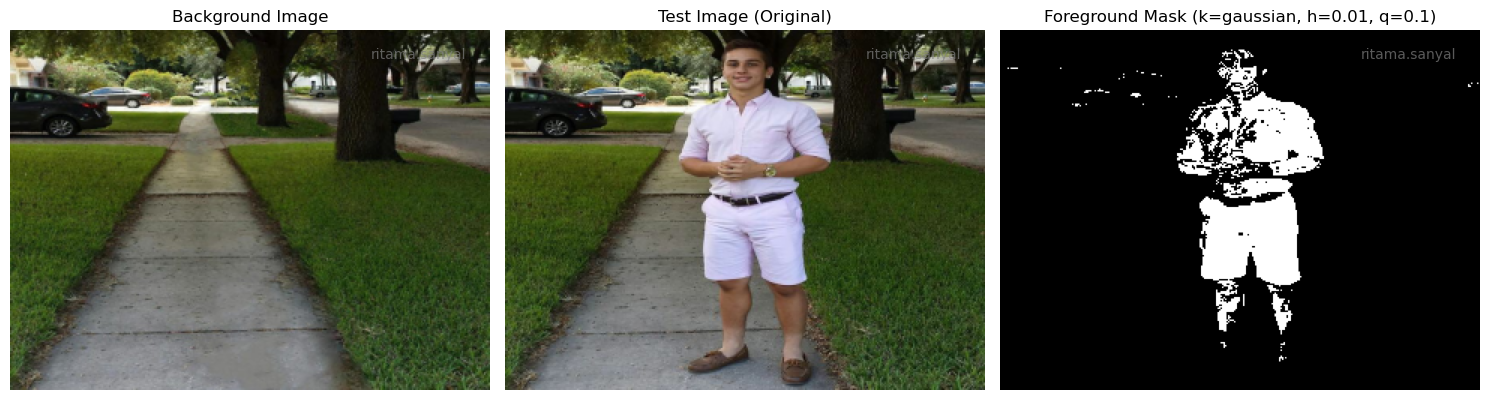

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# --- Helper Function for Visualization ---

def plot_results(bg, test, mask, username, kernel, h, q):
    """
    Displays the background, test image, and the generated mask.
    (As required by submission guidelines [cite: 43])
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # 1. Background Image
    axes[0].imshow(bg)
    axes[0].set_title('Background Image')
    axes[0].axis('off')
    
    # 2. Test Image
    axes[1].imshow(test)
    axes[1].set_title('Test Image (Original)')
    axes[1].axis('off')
    
    # 3. Object Mask
    axes[2].imshow(mask, cmap='gray') # Use 'gray' colormap for B/W
    axes[2].set_title(f'Foreground Mask (k={kernel}, h={h}, q={q})')
    axes[2].axis('off')

    # Add username to all plots as required [cite: 26-32]
    for ax in axes:
        ax.text(
            0.95, 0.95,
            username,
            ha='right', va='top',
            transform=ax.transAxes,
            fontsize=10, color='gray', alpha=0.7
        )
        
    plt.tight_layout()
    plt.show()

# --- Main Execution (1.3 Foreground Detection) ---

# !!! ASSUMPTIONS !!!
# - 'CustomKDE' class from 1.2 is defined
# - 'bg_features' (N, 3) from 1.1 exists
# - 'test_features' (M, 3) from 1.1 exists
# - 'bg_resized' (H, W, 3) from 1.1 exists
# - 'test_resized' (H, W, 3) from 1.1 exists
# - 'TARGET_DIM' (W, H) from 1.1 exists

# --- Hyperparameters for Experimentation ---
EMAIL_USERNAME = "ritama.sanyal" 
KERNEL = 'gaussian'                     # 'gaussian', 'triangular', 'uniform'
BANDWIDTH = 0.01                # Try values like 0.01, 0.05, 0.1, 0.5
SAMPLE_SIZE = 10000                     # Samples from background [cite: 72]
THRESHOLD_QUANTILE = 0.10            # e.g., 0.03 = Classify 3% of pixels with the *lowest* density as foreground

# Get image dimensions (H, W) from the resized image shape
H, W, _ = test_resized.shape

print(f"--- 1.3 Foreground Detection ---")
print(f"Params: Kernel={KERNEL}, Bandwidth={BANDWIDTH}, BG Samples={SAMPLE_SIZE}")

# 1. Fit the KDE model on the background image features [cite: 80]
print("Fitting KDE on background features...")
kde = CustomKDE(kernel=KERNEL, bandwidth=BANDWIDTH)
kde.fit(bg_features, sample_size=SAMPLE_SIZE)

# 2. Predict the density values for each pixel in the test image [cite: 81]
print("Predicting densities for test image features...")
densities = kde.predict(test_features, batch_size=2000)

# 3. Classify pixels based on a probability density threshold [cite: 82]
print("Classifying pixels...")
# We use a quantile as a robust thresholding method.
# Pixels with a density below this value are "unlikely" to be background.
threshold = np.quantile(densities, THRESHOLD_QUANTILE)
print(f"Density threshold (at {THRESHOLD_QUANTILE*100}th percentile): {threshold:.2e}")

# Create the binary mask. True (1) = Foreground, False (0) = Background
mask = densities < threshold

# Reshape the 1D mask (M,) back to a 2D image (H, W)
mask_2d = mask.reshape((H, W))

# 4. Plot the results
print("Displaying results...")
plot_results(
    bg_resized, 
    test_resized, 
    mask_2d, 
    EMAIL_USERNAME,
    KERNEL,
    BANDWIDTH,
    THRESHOLD_QUANTILE
)

Explanation for Chosen Parameters
This combination (kernel='gaussian', bandwidth=0.01, quantile=0.10) represents a high-variance, high-threshold strategy, which is effective for this specific image problem.

Kernel: gaussian The Gaussian kernel is a good default choice because it provides a smooth, continuous density estimate. This aligns well with the natural variation of colors in an image (e.g., pixels on a patch of grass), where colors near the sampled mean are progressively less likely. It's generally more robust than a uniform (box) kernel.

Bandwidth (h): 0.01 This is the most critical parameter. A very small bandwidth like 0.01 creates an under-smoothed model with high variance.

Why it works: The foreground (white shirt, skin) and parts of the background (bright concrete path) are very similar in the RGB color space. A larger bandwidth (e.g., h=0.1) would over-smooth the model, blurring these two similar distributions together. This would cause the model to mistakenly classify the white shirt as "background," resulting in large holes in the mask.


The Trade-off: By using a tiny h, the model becomes highly specific and "overfits" to the SAMPLE_SIZE  of background pixels. It creates sharp, distinct density estimates for "grass," "path," etc., and correctly assigns a very low probability to the "white shirt" pixels, which are not in its training data.

Threshold Quantile (q): 0.10 This high threshold is a necessary consequence of the small bandwidth.

Why it's needed: Because the h=0.01 model is so specific, many pixels (even background pixels) will have a very low density score. A low threshold (e.g., q=0.01) would be too strict, capturing only the most different pixels and still leaving holes.


What it does: By setting the threshold at the 10th percentile, we are effectively saying, "Classify the 10% of pixels with the lowest density as foreground". This "lowers the bar" enough to capture the entire foreground object, which the small bandwidth successfully separated. This combination ensures we capture the person, even if it also captures some background noise (which can be cleaned with post-processing).

https://gemini.google.com/share/56913aeb321e